# RICE LEAF DISEASE DETECTION

## 1. Project Introduction

The objective of this project is to detect and
classify rice leaf diseases using image classification
and deep learning.

### Disease Categories
1. Bacterial Leaf Blight
2. Brown Spot
3. Leaf Smut

## 2. Importing Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

## 3. Dataset Loading

In this section, we load the rice leaf disease dataset
containing three different disease categories.

In [2]:
bacterial = "Bacterial leaf blight-20200814T055237Z-001.zip"
brown_spot = "Brown spot-20200814T055208Z-001.zip"
leaf_smut = "Leaf smut-20200814T055530Z-001.zip"

In [3]:
import zipfile

zipfile.ZipFile(bacterial).extractall("Bacterial_leaf_blight")
zipfile.ZipFile(brown_spot).extractall("Brown_spot")
zipfile.ZipFile(leaf_smut).extractall("Leaf_smut")

In [4]:
from pathlib import Path

print("Bacterial leaf blight:", len(list(Path("Bacterial_leaf_blight").rglob("*.jpg"))))
print("Brown spot:", len(list(Path("Brown_spot").rglob("*.jpg"))))
print("Leaf smut:", len(list(Path("Leaf_smut").rglob("*.jpg"))))

Bacterial leaf blight: 40
Brown spot: 40
Leaf smut: 39


## 4. Creating Dataset DataFrame

In [5]:
df = pd.DataFrame({
    "Disease": ["Bacterial Leaf Blight"] * 40 +
               ["Brown Spot"] * 40 +
               ["Leaf Smut"] * 39
})

df.head()

,Disease
0,Bacterial Leaf Blight
1,Bacterial Leaf Blight
2,Bacterial Leaf Blight
3,Bacterial Leaf Blight
4,Bacterial Leaf Blight


In [6]:
df["Disease"].value_counts()

Disease
Bacterial Leaf Blight    40
Brown Spot               40
Leaf Smut                39
Name: count, dtype: int64

In [7]:
df.tail()

,Disease
114,Leaf Smut
115,Leaf Smut
116,Leaf Smut
117,Leaf Smut
118,Leaf Smut


In [8]:
df.shape

(119, 1)

## Step 5 – Exploratory Data Analysis (EDA)
EDA means understanding our dataset before building a machine learning model.

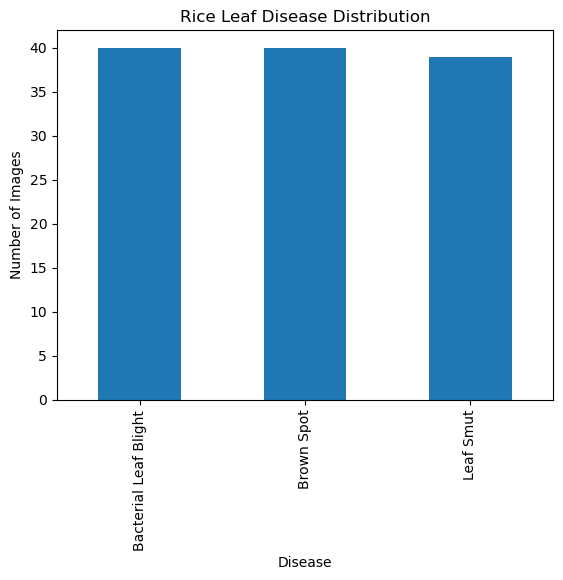

In [9]:
df["Disease"].value_counts().plot(kind="bar")

plt.title("Rice Leaf Disease Distribution")
plt.xlabel("Disease")
plt.ylabel("Number of Images")
plt.show()

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Disease  119 non-null    object
dtypes: object(1)
memory usage: 1.1+ KB


In [11]:
df.describe()

,Disease
count,119
unique,3
top,Bacterial Leaf Blight
freq,40


In [12]:
df.isnull().sum()

Disease    0
dtype: int64

### Display Sample Rice Leaf Images

In [13]:
from pathlib import Path

bacterial = list(Path("Bacterial_leaf_blight").rglob("*.jpg"))
brown = list(Path("Brown_spot").rglob("*.jpg"))
smut = list(Path("Leaf_smut").rglob("*.jpg"))

image_paths = bacterial + brown + smut

labels = (
    ["Bacterial Leaf Blight"] * len(bacterial) +
    ["Brown Spot"] * len(brown) +
    ["Leaf Smut"] * len(smut)
)

image_df = pd.DataFrame({
    "Image_Path": image_paths,
    "Disease": labels
})

image_df.head()

,Image_Path,Disease
0,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight
1,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight
2,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight
3,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight
4,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight


In [14]:
image_df.shape

(119, 2)

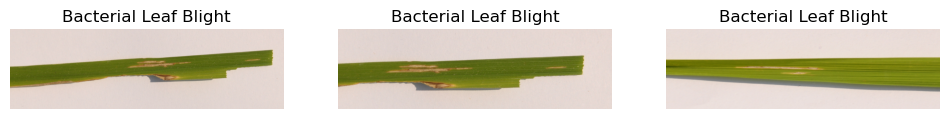

In [15]:
plt.figure(figsize=(12, 5))

for i in range(3):
    img = plt.imread(image_df["Image_Path"][i])

    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(image_df["Disease"][i])
    plt.axis("off")

plt.show()

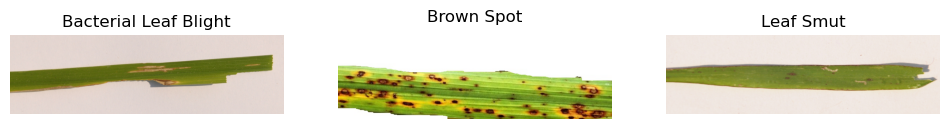

In [16]:
plt.figure(figsize=(12, 5))

for i in [0, 40, 80]:

    img = plt.imread(image_df["Image_Path"][i])

    plt.subplot(1, 3, [0, 40, 80].index(i) + 1)
    plt.imshow(img)
    plt.title(image_df["Disease"][i])
    plt.axis("off")

plt.show()

### Image Dimension Analysis

In [17]:
img = plt.imread(image_df["Image_Path"][0])

print("Image Shape:", img.shape)

Image Shape: (897, 3081, 3)


###  Checking Dimensions of All Images

In [18]:
dimensions = []

for path in image_df["Image_Path"]:
    img = plt.imread(path)
    dimensions.append(img.shape)

image_df["Dimensions"] = dimensions

image_df.head()

,Image_Path,Disease,Dimensions
0,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight,"(897, 3081, 3)"
1,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight,"(897, 3081, 3)"
2,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight,"(897, 3081, 3)"
3,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight,"(897, 3081, 3)"
4,Bacterial_leaf_blight\Bacterial leaf blight\DS...,Bacterial Leaf Blight,"(897, 3081, 3)"


In [19]:
image_df["Dimensions"].value_counts()

Dimensions
(897, 3081, 3)    85
(200, 250, 3)      2
(255, 946, 3)      1
(900, 1200, 3)     1
(80, 376, 3)       1
(73, 367, 3)       1
(71, 301, 3)       1
(409, 614, 3)      1
(233, 948, 3)      1
(250, 766, 3)      1
(211, 948, 3)      1
(216, 537, 3)      1
(174, 503, 3)      1
(383, 510, 3)      1
(233, 565, 3)      1
(217, 562, 3)      1
(170, 311, 3)      1
(168, 359, 3)      1
(104, 467, 3)      1
(94, 340, 3)       1
(92, 286, 3)       1
(88, 296, 3)       1
(514, 768, 3)      1
(193, 427, 3)      1
(127, 316, 3)      1
(124, 456, 3)      1
(197, 699, 3)      1
(268, 763, 3)      1
(224, 765, 3)      1
(323, 1504, 3)     1
(279, 1480, 3)     1
(371, 1530, 3)     1
(244, 617, 3)      1
(291, 741, 3)      1
Name: count, dtype: int64

### Checking Corrupted Images

In [20]:
from PIL import Image

corrupted = 0

for path in image_df["Image_Path"]:
    try:
        Image.open(path).verify()
    except:
        corrupted += 1

print("Corrupted Images:", corrupted)

Corrupted Images: 0


###  EDA Observations

1. The dataset contains 119 rice leaf images.
2. There are three disease categories.
3. The dataset has no missing disease labels.
4. All images are readable and non-corrupted.
5. Images have different dimensions.
6. All images contain three RGB colour channels.
7. The dataset has a nearly balanced class distribution.

## 6. Image Preprocessing

In [21]:
img = plt.imread(image_df["Image_Path"][0])

In [23]:
resized_img = tf.image.resize(img, (224, 224)) ## In this section, all rice leaf images are resized
# to a fixed dimension of 224 × 224 pixels.

In [24]:
print("Original Image Shape:", img.shape)
print("Resized Image Shape:", resized_img.shape)

Original Image Shape: (897, 3081, 3)
Resized Image Shape: (224, 224, 3)


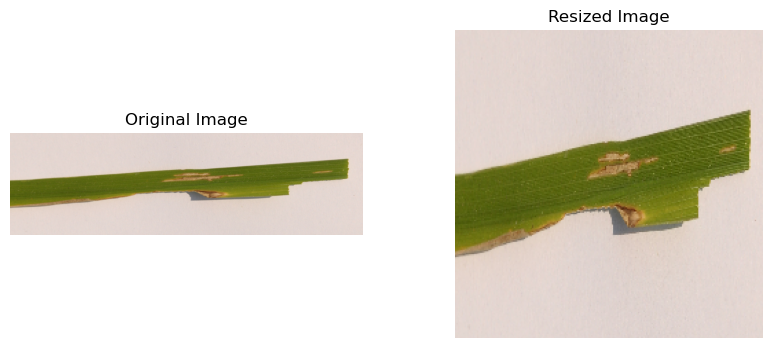

In [26]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_img.numpy().astype("uint8"))
plt.title("Resized Image")
plt.axis("off")

plt.show()  ##Comparing Original and Resized Images

### Resizing All Dataset Images

In [27]:
resized_images = []

for path in image_df["Image_Path"]:
    img = plt.imread(path)
    img = tf.image.resize(img, (224, 224))
    resized_images.append(img)

print("Total Resized Images:", len(resized_images))

Total Resized Images: 119


In [28]:
print(resized_images[0].shape)

(224, 224, 3)


### Image Normalization
Normalization means converting image pixel values into a smaller numerical range.

In [29]:
normalized_images = []

for img in resized_images:
    img = img / 255.0
    normalized_images.append(img)

print("Total Normalized Images:", len(normalized_images))

Total Normalized Images: 119


In [30]:
print("Minimum Pixel Value:", np.min(normalized_images[0]))
print("Maximum Pixel Value:", np.max(normalized_images[0]))

Minimum Pixel Value: 0.0005000446
Maximum Pixel Value: 0.936523


### Label Encoding

In [31]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

labels = encoder.fit_transform(image_df["Disease"])

print("Disease Classes:", encoder.classes_)
print("Encoded Labels:", labels[:5])

Disease Classes: ['Bacterial Leaf Blight' 'Brown Spot' 'Leaf Smut']
Encoded Labels: [0 0 0 0 0]


### Train-Test Split

In [33]:
X = np.array(normalized_images)
y = labels

print("Image Data Shape:", X.shape)
print("Label Data Shape:", y.shape)

Image Data Shape: (119, 224, 224, 3)
Label Data Shape: (119,)


In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y # Each set maintains approximately the same class proportions as the original dataset.It reduces the risk of a disease class being underrepresented in a split.
)

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))
print("Total Images:", len(X_train) + len(X_test))


Training Images: 95
Testing Images: 24
Total Images: 119


### Data Augmentation

It is a technique used to create variations of existing training images. It helps the model learn from different image orientations and appearances.

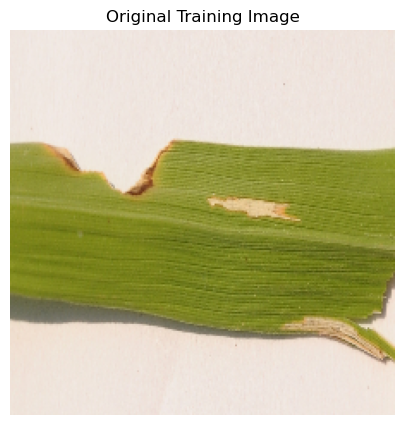

In [38]:
plt.figure(figsize=(5, 5))

plt.imshow(X_train[0])
plt.title("Original Training Image")
plt.axis("off")

plt.show()

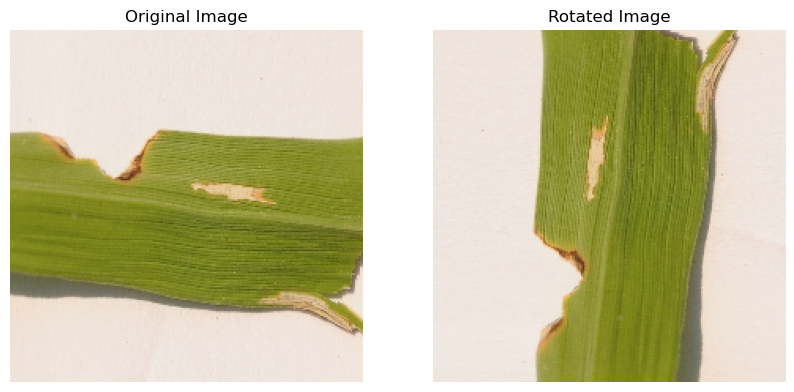

In [39]:
rotated_img = tf.image.rot90(X_train[0])

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(X_train[0])
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_img)
plt.title("Rotated Image")
plt.axis("off")

plt.show()

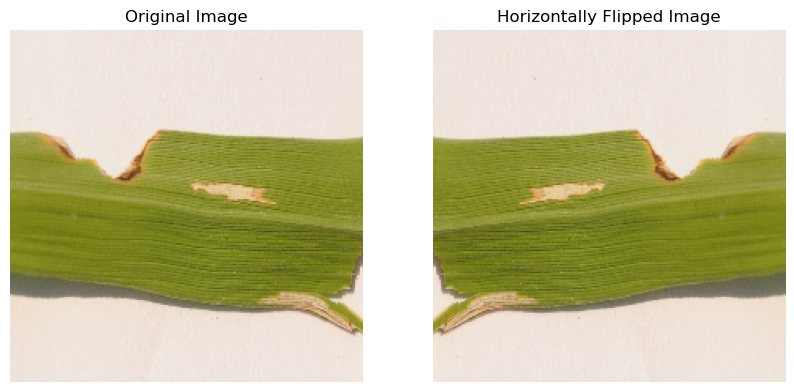

In [40]:
flipped_img = tf.image.flip_left_right(X_train[0])

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(X_train[0])
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(flipped_img)
plt.title("Horizontally Flipped Image")
plt.axis("off")

plt.show()

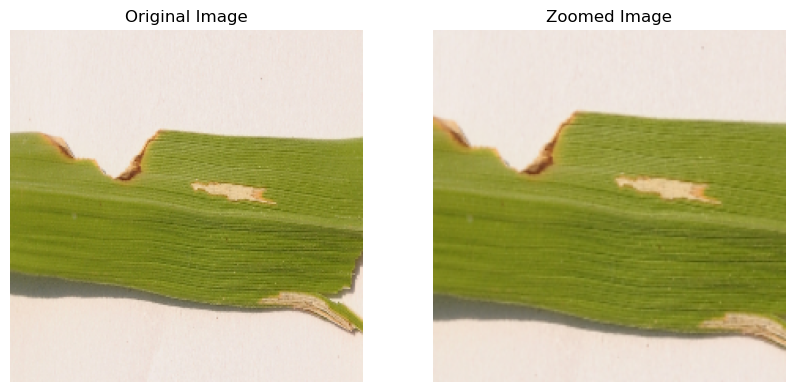

In [41]:
zoomed_img = tf.image.central_crop(X_train[0], central_fraction=0.8)

zoomed_img = tf.image.resize(zoomed_img, (224, 224))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(X_train[0])
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(zoomed_img)
plt.title("Zoomed Image")
plt.axis("off")

plt.show()

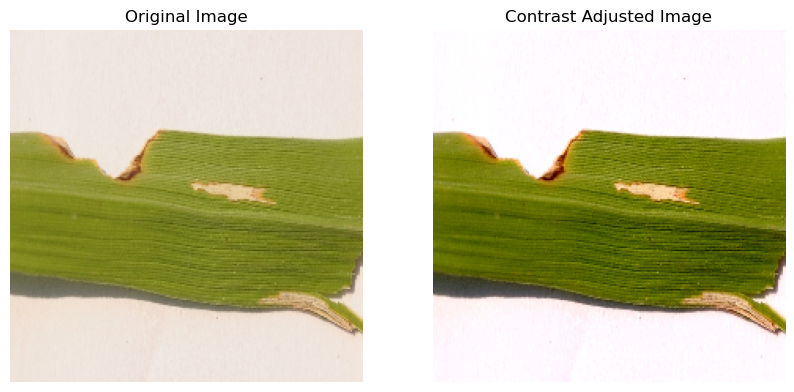

In [43]:
contrast_img = tf.image.adjust_contrast(X_train[0], 1.5)

contrast_img = tf.clip_by_value(contrast_img, 0.0, 1.0)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(X_train[0])
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_img)
plt.title("Contrast Adjusted Image")
plt.axis("off")

plt.show()

In [44]:
rotated_images = []

for img in X_train:
    rotated = tf.image.rot90(img)
    rotated = tf.image.resize(rotated, (224, 224))
    rotated_images.append(rotated)

print("Original Training Images:", len(X_train))
print("Rotated Training Images:", len(rotated_images))

Original Training Images: 95
Rotated Training Images: 95


In [45]:
flipped_images = []

for img in X_train:
    flipped = tf.image.flip_left_right(img)
    flipped_images.append(flipped)

print("Original Training Images:", len(X_train))
print("Flipped Training Images:", len(flipped_images))

Original Training Images: 95
Flipped Training Images: 95


In [46]:
zoomed_images = []

for img in X_train:
    zoomed = tf.image.central_crop(img, central_fraction=0.8)
    zoomed = tf.image.resize(zoomed, (224, 224))
    zoomed_images.append(zoomed)

print("Original Training Images:", len(X_train))
print("Zoomed Training Images:", len(zoomed_images))

Original Training Images: 95
Zoomed Training Images: 95


In [47]:
contrast_images = []

for img in X_train:
    contrast = tf.image.adjust_contrast(img, 1.5)
    contrast = tf.clip_by_value(contrast, 0.0, 1.0)
    contrast_images.append(contrast)

print("Original Training Images:", len(X_train))
print("Contrast Adjusted Images:", len(contrast_images))

Original Training Images: 95
Contrast Adjusted Images: 95


In [48]:
X_train_augmented = np.concatenate([
    X_train,
    rotated_images,
    flipped_images,
    zoomed_images,
    contrast_images
])

y_train_augmented = np.tile(y_train, 5)

print("Before Augmentation:", len(X_train))
print("After Augmentation:", len(X_train_augmented))
print("Training Labels:", len(y_train_augmented))

Before Augmentation: 95
After Augmentation: 475
Training Labels: 475


##  Data Augmentation Analysis

Data augmentation was performed to increase the variety of training images and help reduce overfitting.

The following techniques were applied:

1. Rotation – Rotated images by 90 degrees.
2. Horizontal Flip – Flipped images horizontally.
3. Zoom – Cropped the central 80% and resized the images.
4. Contrast Adjustment – Increased image contrast.

### Results

- Original training images: 95
- Augmented training images: 475
- Testing images: 24

### Conclusion

Data augmentation created different variations of the original training images. These variations helped the CNN learn image patterns from different orientations, sizes and lighting conditions.

### Build CNN Model

In [50]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(3, activation='softmax')
])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [51]:
## Compile the CNN Model.

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [52]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### Train CNN Model

In [53]:
history = model.fit(
    X_train_augmented,
    y_train_augmented,
    epochs=10,
    batch_size=16
)

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 398ms/step - accuracy: 0.3958 - loss: 1.3181
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 402ms/step - accuracy: 0.4989 - loss: 0.9588
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 378ms/step - accuracy: 0.5895 - loss: 0.8703
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 387ms/step - accuracy: 0.6716 - loss: 0.7321
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 402ms/step - accuracy: 0.7411 - loss: 0.6136
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 399ms/step - accuracy: 0.7705 - loss: 0.5460
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 394ms/step - accuracy: 0.8147 - loss: 0.4504
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 400ms/step - accuracy: 0.8232 - loss: 0.4084
Epoch 9/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 399ms/step - accuracy: 0.8968 - loss: 0.3126
Epoch 10/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 403ms/step - accuracy: 0.8716 - loss: 0.2913


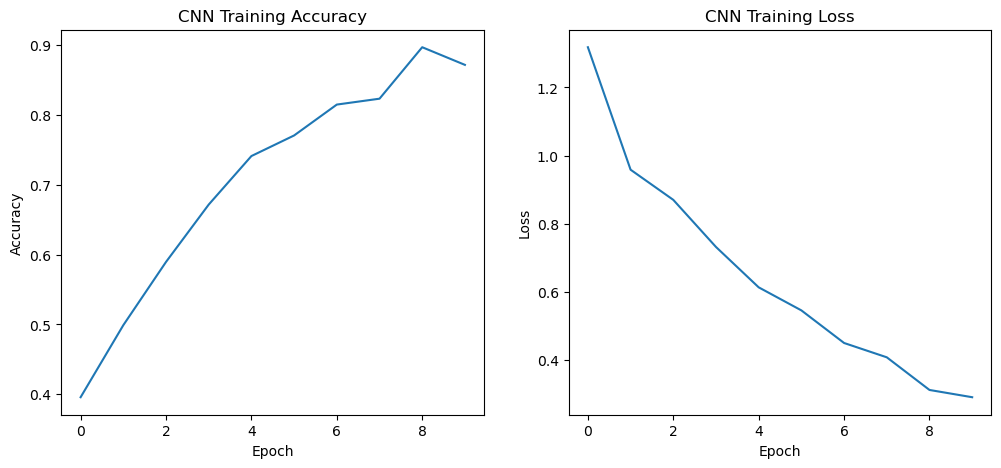

In [54]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.title("CNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.show()

### Model Evaluation

In [55]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step - accuracy: 0.7083 - loss: 0.5176
Test Accuracy: 70.83333134651184 %
Test Loss: 0.5175566673278809


### Classification Report

In [56]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(
    y_test,
    y_pred_classes,
    target_names=encoder.classes_
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.75      0.75      0.75         8
           Brown Spot       0.57      0.50      0.53         8
            Leaf Smut       0.78      0.88      0.82         8

             accuracy                           0.71        24
            macro avg       0.70      0.71      0.70        24
         weighted avg       0.70      0.71      0.70        24



### Confusion Matrix

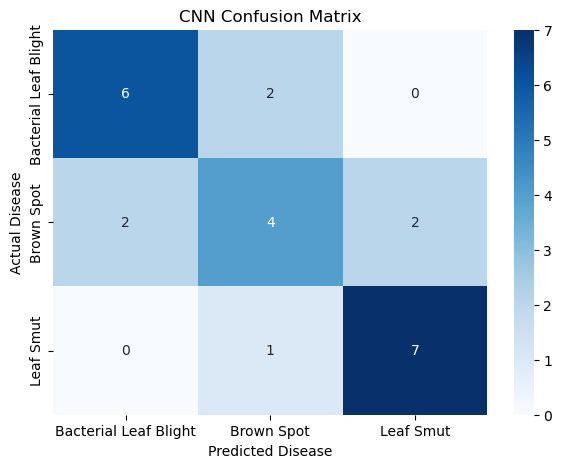

In [57]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.show()

### second CNN model

In [58]:
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation='relu'),

    tf.keras.layers.Dense(3, activation='softmax')
])

print("Second CNN Model Created Successfully!")

Second CNN Model Created Successfully!


In [59]:
model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Second CNN Model Compiled Successfully!")

Second CNN Model Compiled Successfully!


In [60]:
history2 = model2.fit(
    X_train_augmented,
    y_train_augmented,
    epochs=10,
    batch_size=16
)

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 269ms/step - accuracy: 0.4021 - loss: 1.3903
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 274ms/step - accuracy: 0.5368 - loss: 0.9435
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 272ms/step - accuracy: 0.6505 - loss: 0.7545
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 274ms/step - accuracy: 0.7895 - loss: 0.5451
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 270ms/step - accuracy: 0.8295 - loss: 0.3973
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 275ms/step - accuracy: 0.9158 - loss: 0.2291
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 274ms/step - accuracy: 0.9642 - loss: 0.1243
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 276ms/step - accuracy: 0.9916 - loss: 0.0628
Epoch 9/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 270ms/step - accuracy: 1.0000 - loss: 0.0172
Epoch 10/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 280ms/step - accuracy: 1.0000 - loss: 0.0127


In [61]:
test_loss2, test_accuracy2 = model2.evaluate(X_test, y_test)

print("Model 2 Test Accuracy:", test_accuracy2 * 100, "%")
print("Model 2 Test Loss:", test_loss2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - accuracy: 0.5417 - loss: 1.3587
Model 2 Test Accuracy: 54.16666865348816 %
Model 2 Test Loss: 1.3586626052856445


## Model Comparison Report

Two CNN architectures were trained and evaluated.

### Model 1
- Training Accuracy: 87.16%
- Testing Accuracy: 70.83%
- Testing Loss: 0.5176

### Model 2
- Training Accuracy: 100%
- Testing Accuracy: 54.17%
- Testing Loss: 1.3587

### Analysis

Model 1 performed better on the unseen test dataset.
Model 2 achieved 100% training accuracy but showed
lower testing accuracy, indicating overfitting.

### Conclusion

Based on the current experimental results, Model 1
is the better-performing CNN architecture.

#  Challenges Faced

During the Rice Leaf Disease Detection project, several
challenges were identified.

### 1. Dataset Size
Challenge: The dataset contained only 119 images instead
of the 120 images mentioned in the assignment.

Solution: Continued the project using the available images.

### 2. Different Image Dimensions
Challenge: Images had different heights and widths.

Solution: Resized all images to 224 × 224 pixels.

### 3. Image Quality
Challenge: Image files needed to be checked for corruption.

Solution: Verified the images and found no corrupted files.

### 4. Small Training Dataset
Challenge: A small dataset can cause overfitting.

Solution: Applied rotation, horizontal flipping, zoom,
and contrast adjustment.

### 5. Model Overfitting
Challenge: The second CNN achieved 100% training accuracy
but only 54.17% testing accuracy.

Solution: Used test performance to compare both models
and identify the better-performing architecture.

### 6. Limited Computing Resources
Challenge: TensorFlow GPU support was unavailable
in the native Windows environment.

Solution: Used CPU-based model training.

### Conclusion
The challenges were addressed using image preprocessing,
data augmentation, model evaluation, and comparison.

#  Project Conclusion

The Rice Leaf Disease Detection project was developed
using Deep Learning and Convolutional Neural Networks.

The dataset contained 119 images belonging to three
disease categories:
1. Bacterial Leaf Blight
2. Brown Spot
3. Leaf Smut

Image preprocessing techniques such as resizing,
normalization, and label encoding were performed.

Data augmentation techniques including rotation,
horizontal flipping, zoom, and contrast adjustment
were applied to the training images.

Two CNN models were developed and evaluated.

Model 1 achieved 70.83% test accuracy, while Model 2
achieved 54.17% test accuracy.

Based on the current experimental results, Model 1
performed better on the test dataset.

This project demonstrates how Deep Learning can be
used to classify rice leaf diseases using images.

Further improvement can be achieved by collecting
more images and improving model generalization.